# Лабораторная работа №2
Меркулов Роман Александрович 9 группа

## 1.Импорт зависимостей и объявление переменных

In [41]:
import numpy as np
import matplotlib.pyplot as plt

meander_freq = 4   
meander_amp = 1
meander_periods = 3

carrier_freq = 12 * meander_freq
carrier_amp = 1

duration = meander_periods / meander_freq
sampling_rate = 25 * carrier_freq 
num_samples = int(duration * sampling_rate)
time = np.linspace(0, duration, num_samples, endpoint=False)

am_depth = 0.8   
pm_index = 1.2     
fm_deviation = 20       

## 2. Модулирующий сигнал (меандр)

In [42]:
def meandr(f, t, A=1.0):
    return A * 0.5 * (1 + np.sign(np.sin(2 * np.pi * f * t)))

Также выведем его график, чтобы понимать, с чем мы вообще работаем

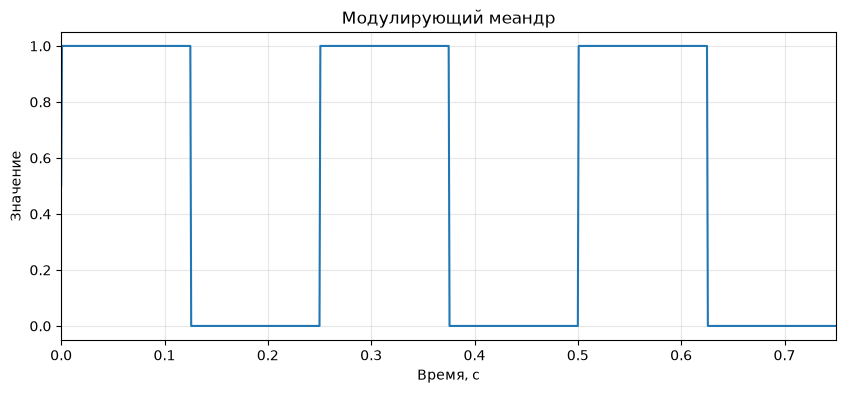

In [43]:
plt.figure(figsize=(10, 4))
plt.plot(time, meandr(meander_freq, time, meander_amp))
plt.title(f'Модулирующий меандр')
plt.xlabel('Время, с')
plt.ylabel('Значение')
plt.grid(alpha=0.3)
plt.xlim(0, duration)
plt.show()

Далее выведем график несущей гармоники

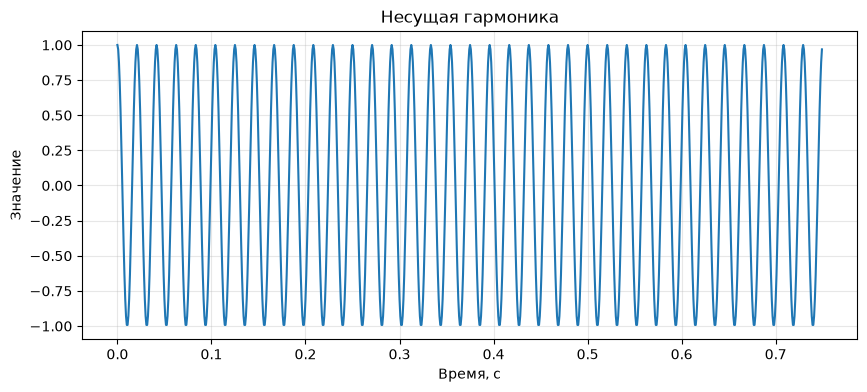

In [44]:
def carrier(t, freq, amp=1.0):
    return amp * np.cos(2 * np.pi * freq * t)

plt.figure(figsize=(10, 4))
plt.plot(time, carrier(time, carrier_freq, carrier_amp))
plt.title(f'Несущая гармоника')
plt.xlabel('Время, с')
plt.ylabel('Значение')
plt.grid(alpha=0.3)
plt.show()

Также выведем совмещенный график меандра и гармоники в один период

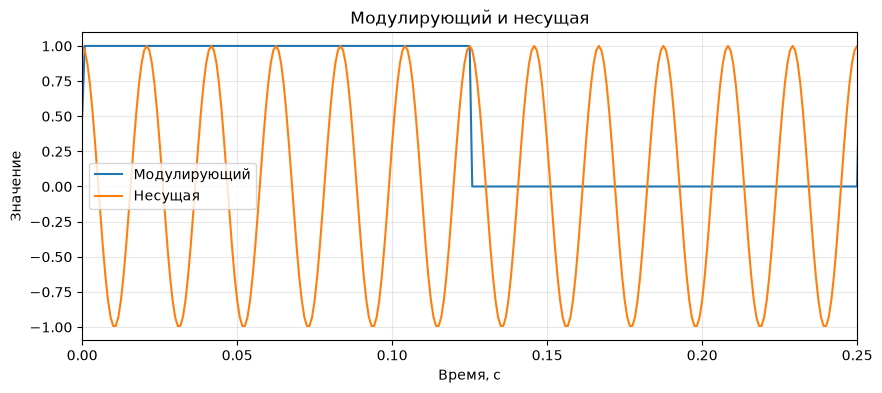

In [45]:
t_show = 1 / meander_freq

plt.figure(figsize=(10, 4))
plt.plot(time, meandr(meander_freq, time, meander_amp), label='Модулирующий')
plt.plot(time, carrier(time, carrier_freq, carrier_amp), label='Несущая')
plt.xlim(0, t_show)
plt.title('Модулирующий и несущая')
plt.xlabel('Время, с')
plt.ylabel('Значение')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3. АМ-сигнал

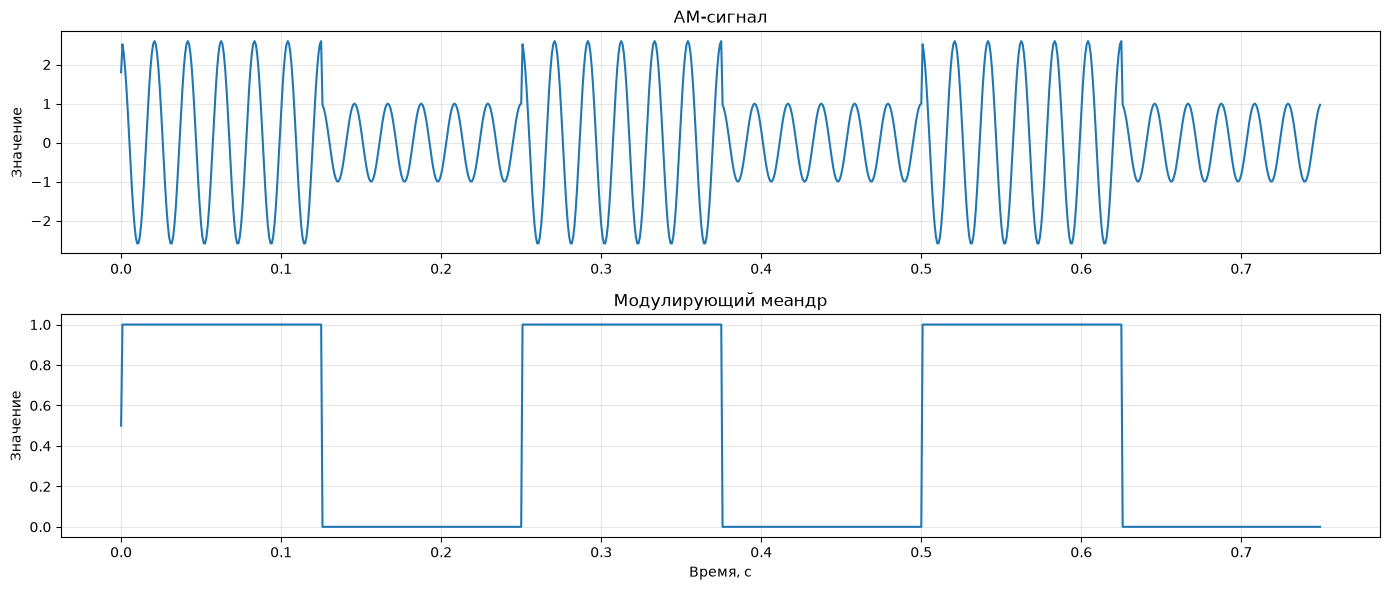

In [46]:
am_signal = (carrier_amp + am_depth * (2 * meandr(meander_freq, time, meander_amp))) * np.cos(2 * np.pi * carrier_freq * time)

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

axes[0].plot(time, am_signal)
axes[0].set_title('АМ-сигнал')
axes[0].set_ylabel('Значение')
axes[0].grid(alpha=0.3)

axes[1].plot(time, meandr(meander_freq, time, meander_amp))
axes[1].set_title('Модулирующий меандр')
axes[1].set_ylabel('Значение')
axes[1].set_xlabel('Время, с')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 4. ФМ-сигнал

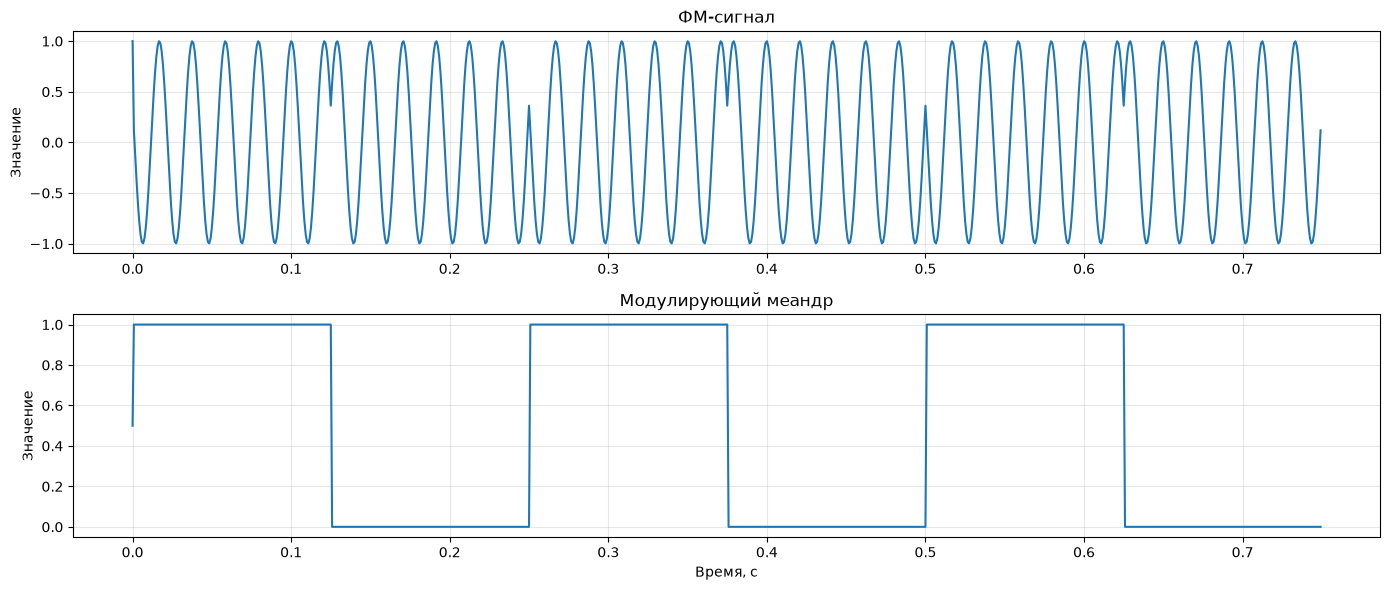

In [47]:
pm = carrier_amp * np.cos(2 * np.pi * carrier_freq * time + pm_index * (2 * meandr(meander_freq, time, meander_amp) - 1))

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

axes[0].plot(time, pm)
axes[0].set_title('ФМ-сигнал')
axes[0].set_ylabel('Значение')
axes[0].grid(alpha=0.3)

axes[1].plot(time, meandr(meander_freq, time, meander_amp))
axes[1].set_title('Модулирующий меандр')
axes[1].set_ylabel('Значение')
axes[1].set_xlabel('Время, с')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. ЧМ-сигнал

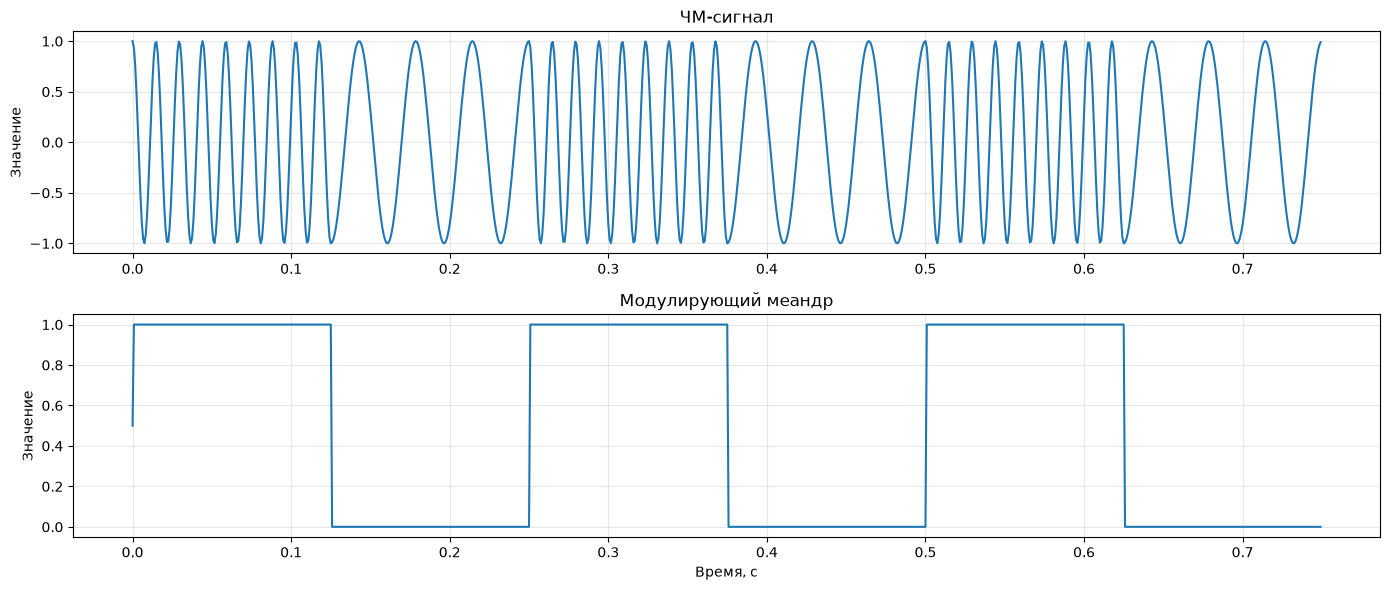

In [48]:
phase_fm = (2 * np.pi * carrier_freq * time + 2 * np.pi * fm_deviation * np.cumsum(2 * meandr(meander_freq, time, meander_amp) - 1)  / sampling_rate)
fm = carrier_amp * np.cos(phase_fm)

fig, axes = plt.subplots(2, 1, figsize=(14, 6))

axes[0].plot(time, fm)
axes[0].set_title('ЧМ-сигнал')
axes[0].set_ylabel('Значение')
axes[0].grid(alpha=0.3)

axes[1].plot(time, meandr(meander_freq, time, meander_amp))
axes[1].set_title('Модулирующий меандр')
axes[1].set_ylabel('Значение')
axes[1].set_xlabel('Время, с')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Спектр для АМ, ФМ, ЧМ

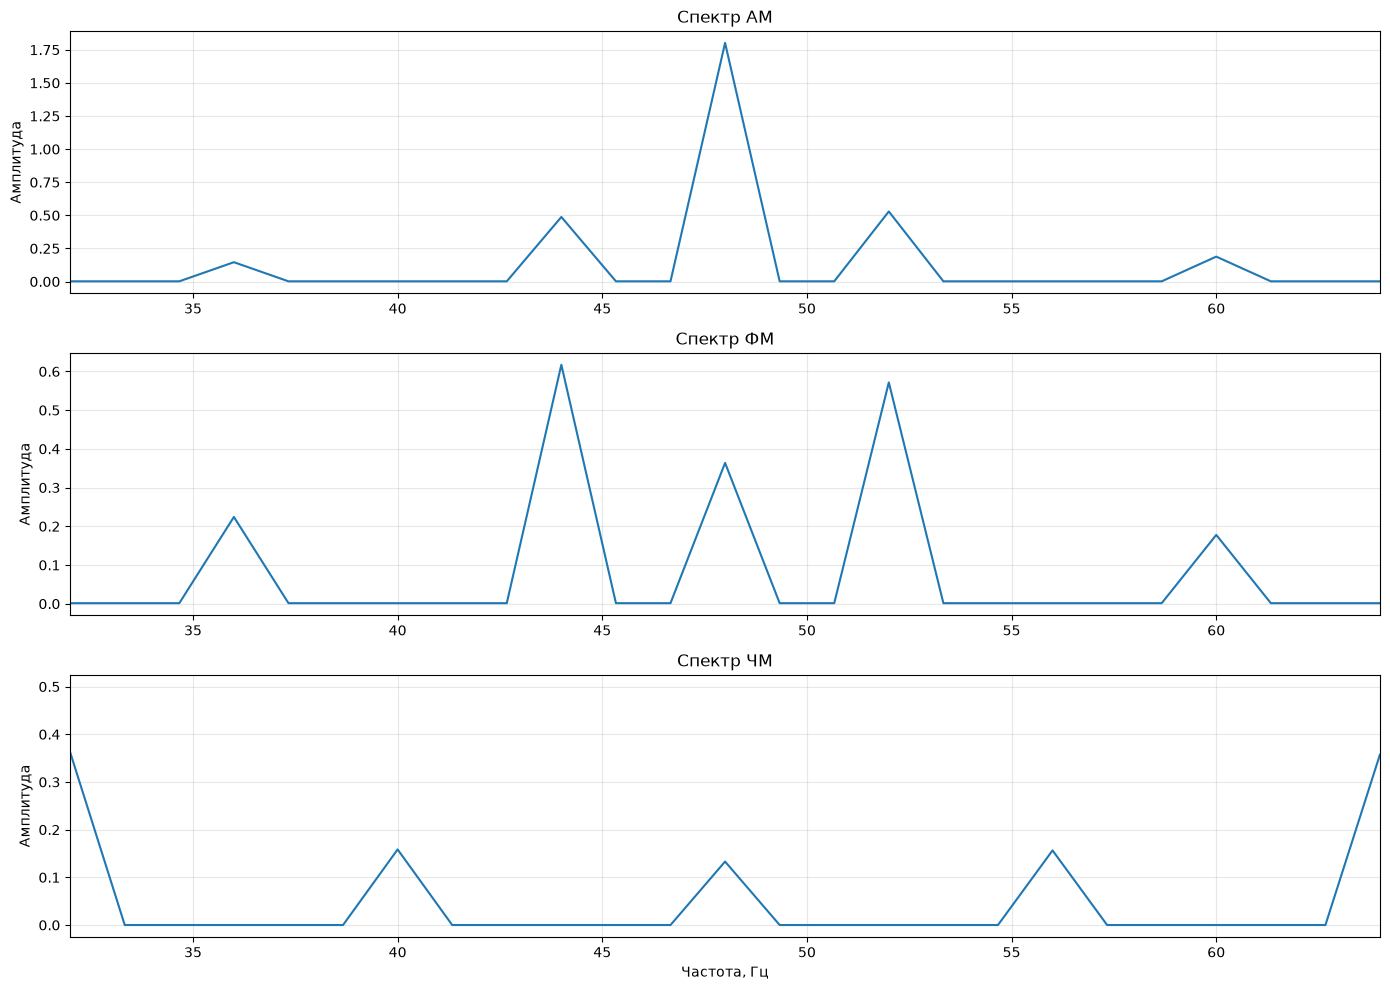

In [52]:
def get_spectrum(signal, fs):
    N = len(signal)
    X = np.abs(np.fft.fft(signal)) / N * 2
    freqs = np.fft.fftfreq(N, d=1/fs)
    mask = freqs >= 0
    return freqs[mask], X[mask]


f_am, a_am = get_spectrum(am_signal, sampling_rate)
f_pm, a_pm = get_spectrum(pm, sampling_rate)
f_fm, a_fm = get_spectrum(fm, sampling_rate)

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

axes[0].plot(f_am, a_am)
axes[0].set_xlim(carrier_freq - carrier_freq/3, carrier_freq + carrier_freq/3)
axes[0].set_title('Спектр АМ')
axes[0].set_ylabel('Амплитуда')
axes[0].grid(alpha=0.3)

axes[1].plot(f_pm, a_pm)
axes[1].set_xlim(carrier_freq - carrier_freq/3, carrier_freq + carrier_freq/3)
axes[1].set_title('Спектр ФМ')
axes[1].set_ylabel('Амплитуда')
axes[1].grid(alpha=0.3)

axes[2].plot(f_fm, a_fm)
axes[2].set_xlim(carrier_freq - carrier_freq/3, carrier_freq + carrier_freq/3)
axes[2].set_title('Спектр ЧМ')
axes[2].set_xlabel('Частота, Гц')
axes[2].set_ylabel('Амплитуда')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()